In [1]:
import torch

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [14]:
x =torch.linspace(-2, 2, 50)

In [15]:
x

tensor([-2.0000, -1.9184, -1.8367, -1.7551, -1.6735, -1.5918, -1.5102, -1.4286,
        -1.3469, -1.2653, -1.1837, -1.1020, -1.0204, -0.9388, -0.8571, -0.7755,
        -0.6939, -0.6122, -0.5306, -0.4490, -0.3673, -0.2857, -0.2041, -0.1224,
        -0.0408,  0.0408,  0.1224,  0.2041,  0.2857,  0.3673,  0.4490,  0.5306,
         0.6122,  0.6939,  0.7755,  0.8571,  0.9388,  1.0204,  1.1020,  1.1837,
         1.2653,  1.3469,  1.4286,  1.5102,  1.5918,  1.6735,  1.7551,  1.8367,
         1.9184,  2.0000])

In [16]:
x =torch.linspace(-2, 2, 50).unsqueeze(1).to(device)

In [17]:
x

tensor([[-2.0000],
        [-1.9184],
        [-1.8367],
        [-1.7551],
        [-1.6735],
        [-1.5918],
        [-1.5102],
        [-1.4286],
        [-1.3469],
        [-1.2653],
        [-1.1837],
        [-1.1020],
        [-1.0204],
        [-0.9388],
        [-0.8571],
        [-0.7755],
        [-0.6939],
        [-0.6122],
        [-0.5306],
        [-0.4490],
        [-0.3673],
        [-0.2857],
        [-0.2041],
        [-0.1224],
        [-0.0408],
        [ 0.0408],
        [ 0.1224],
        [ 0.2041],
        [ 0.2857],
        [ 0.3673],
        [ 0.4490],
        [ 0.5306],
        [ 0.6122],
        [ 0.6939],
        [ 0.7755],
        [ 0.8571],
        [ 0.9388],
        [ 1.0204],
        [ 1.1020],
        [ 1.1837],
        [ 1.2653],
        [ 1.3469],
        [ 1.4286],
        [ 1.5102],
        [ 1.5918],
        [ 1.6735],
        [ 1.7551],
        [ 1.8367],
        [ 1.9184],
        [ 2.0000]])

In [22]:
noise =0.6 *torch.randn_like(x).to(device)
y = 3 * x + 2 + noise

In [23]:
import matplotlib.pyplot as plt


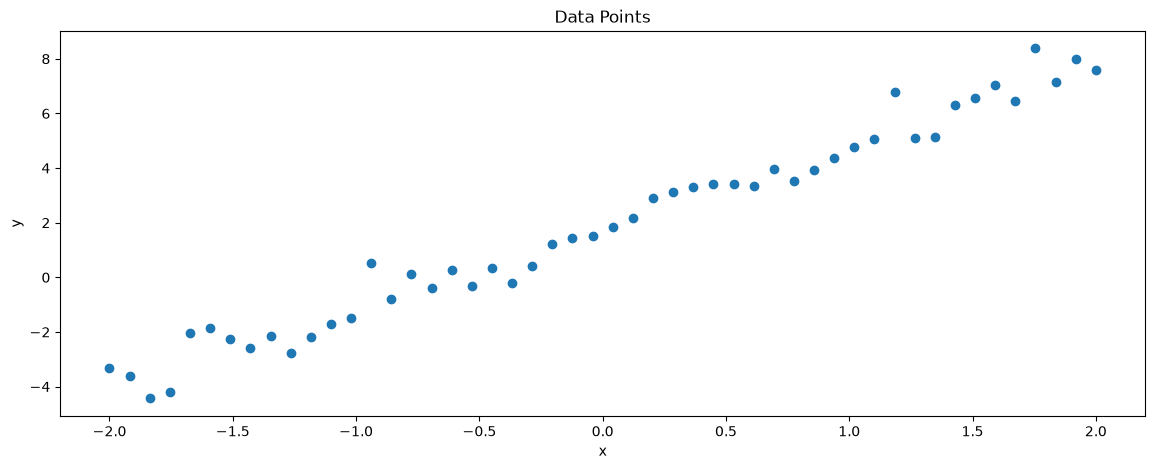

In [24]:
plt.figure(figsize=(14, 5))
plt.scatter(x.cpu(), y.cpu())
plt.xlabel('x')
plt.ylabel('y')
plt.title('Data Points')
plt.show()

In [25]:
import torch.nn as nn

In [26]:
model = nn.Linear(1, 1).to(device)

In [44]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)
epochs = 100
losses = []
for epoch in range(epochs):
    y_pred = model(x)
    loss = loss_function(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    optimizer.zero_grad()
    if epoch % 100 == 0:
        print(f'Epoch {epoch}/{epochs}, Loss: {loss.item()}')


Epoch 0/100, Loss: 0.3282736539840698


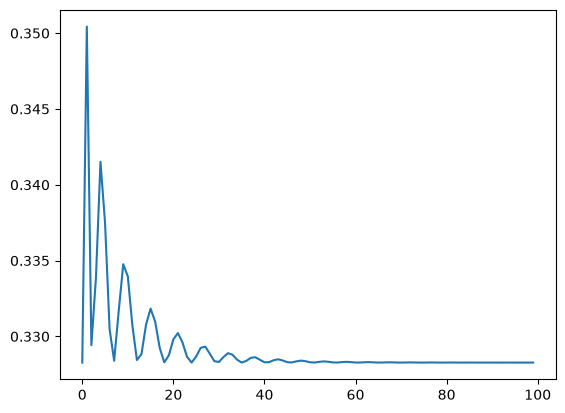

In [45]:
plt.plot(losses)

In [38]:
with torch.inference_mode():
    y_pred = model(x)

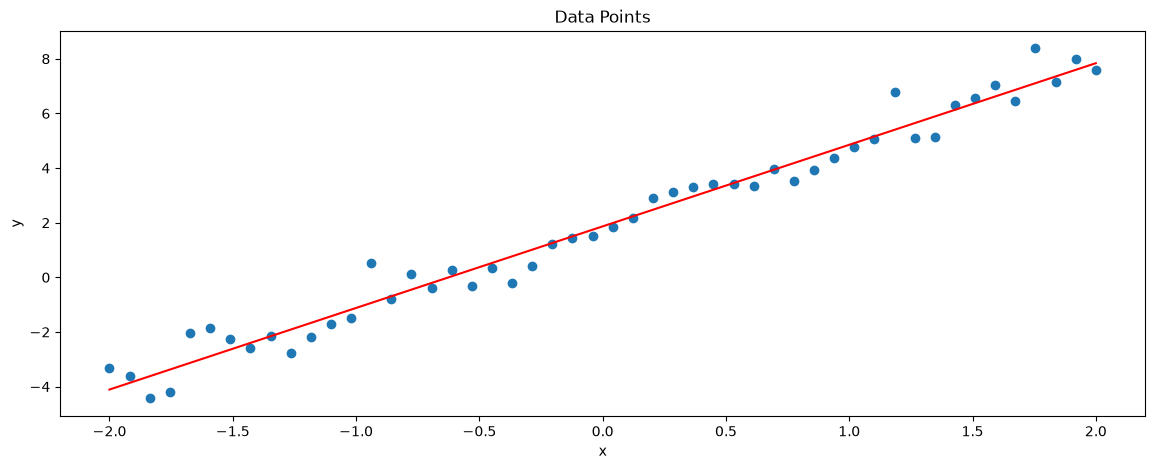

In [39]:
plt.figure(figsize=(14, 5))
plt.scatter(x.cpu(), y.cpu())
plt.plot(x.cpu(), y_pred.cpu(), color='red', label='Regression Line')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Data Points')
plt.show()

In [40]:
from torcheval.metrics import R2Score

In [41]:
r2_metric = R2Score()
r2_metric.update(y_pred.cpu(), y.cpu())
print(f'R² Score: {r2_metric.compute().item():.4f}')

R² Score: 0.9742
